# Linear ODE Problem Set Solutions

**References:** `Notes/problem_set_III.pdf` (Q1), `Notes/Problem Set II.pdf` (Q1, Q3), `Notes/lec9.pdf`, `Notes/lec11.pdf`

Grouped by question type:
1. **Type 1:** 1st-Order Explicit vs Implicit Euler (`problem_set_III.pdf` Q1)
2. **Type 2:** 2nd-Order Driven Damped Oscillator & Overdamped Reduction (`Problem Set II.pdf` Q1)
3. **Type 3:** 2D Linear Systems Classification & Why Euler Fails on Centers (`Problem Set II.pdf` Q3)

---
## Type 1: Explicit vs Implicit Euler (`problem_set_III.pdf` Q1)
Equation: $\frac{dy}{dt} = -\lambda y$.
- **Explicit Euler:** $y_{n+1} = y_n(1 - \lambda\Delta t)$ -> blows up if $\Delta t > 2/\lambda$.
- **Implicit Euler:** $y_{n+1} = y_n / (1 + \lambda\Delta t)$ -> always stable for any $\Delta t > 0$.

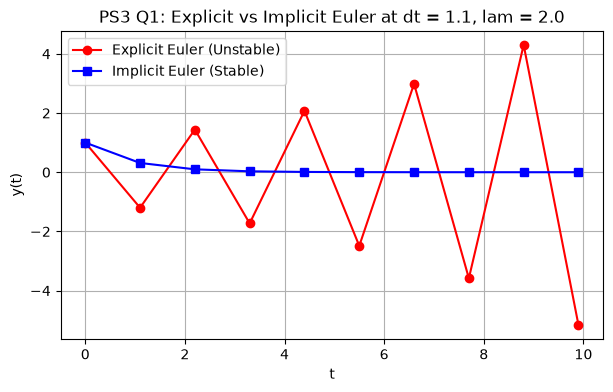

In [1]:
import numpy as np
import matplotlib.pyplot as plt

lam = 2.0   # stability limit for explicit Euler is dt < 2/lam = 1.0
y0 = 1.0
dt = 1.1    # larger than 2/lam -> explicit blows up, implicit stays stable

t = np.arange(0, 10, dt)
n = len(t)
y_exp = np.zeros(n)
y_imp = np.zeros(n)
y_exp[0] = y0
y_imp[0] = y0

for i in range(n - 1):
    y_exp[i + 1] = y_exp[i] * (1 - lam * dt)
    y_imp[i + 1] = y_imp[i] / (1 + lam * dt)

plt.figure(figsize=(7, 4))
plt.plot(t, y_exp, 'r-o', label='Explicit Euler (Unstable)')
plt.plot(t, y_imp, 'b-s', label='Implicit Euler (Stable)')
plt.xlabel('t')
plt.ylabel('y(t)')
plt.title(f'PS3 Q1: Explicit vs Implicit Euler at dt = {dt}, lam = {lam}')
plt.legend()
plt.grid(True)
plt.show()

---
## Type 2: Driven Damped Harmonic Oscillator (`Problem Set II.pdf` Q1)
Equation: $m\ddot{x} + \gamma\dot{x} + kx = A\sin(\omega t)$ with $m=0.5,\; \gamma=1,\; k=1,\; \omega=2\pi,\; A=1,\; x(0)=3,\; \dot{x}(0)=5$.

- **Overdamped approximation (dropping $m\ddot{x}$):** $\gamma\dot{x} + kx = A\sin(\omega t)$.
- Valid when viscous damping dominates inertia: $\gamma^2 \gg mk$, and driving frequency $\omega$ is not too large compared to $\gamma/m$. Here $m\ddot{x}$ matters at early $t$ (and at high $\omega = 2\pi$).

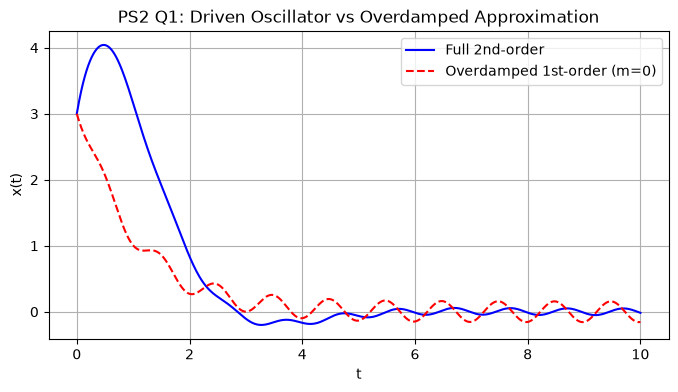

In [2]:
# Full 2nd-order system vs Overdamped 1st-order reduction using RK4
m, gamma, k, A = 0.5, 1.0, 1.0, 1.0
omega = 2 * np.pi
dt = 0.01
t = np.arange(0, 10 + dt, dt)
n = len(t)

# Full system: y[0] = x, y[1] = v
y = np.zeros((2, n))
y[:, 0] = [3.0, 5.0]

# Reduced 1st-order system: gamma * x_dot + k * x = A * sin(omega * t)
x_red = np.zeros(n)
x_red[0] = 3.0

def f_full(t_val, state):
    x_val, v_val = state[0], state[1]
    return np.array([v_val, (A * np.sin(omega * t_val) - gamma * v_val - k * x_val) / m])

def f_red(t_val, x_val):
    return (A * np.sin(omega * t_val) - k * x_val) / gamma

for i in range(n - 1):
    k1 = f_full(t[i], y[:, i])
    k2 = f_full(t[i] + 0.5*dt, y[:, i] + 0.5*dt*k1)
    k3 = f_full(t[i] + 0.5*dt, y[:, i] + 0.5*dt*k2)
    k4 = f_full(t[i] + dt, y[:, i] + dt*k3)
    y[:, i + 1] = y[:, i] + dt * (k1 + 2*k2 + 2*k3 + k4) / 6

    r1 = f_red(t[i], x_red[i])
    r2 = f_red(t[i] + 0.5*dt, x_red[i] + 0.5*dt*r1)
    r3 = f_red(t[i] + 0.5*dt, x_red[i] + 0.5*dt*r2)
    r4 = f_red(t[i] + dt, x_red[i] + dt*r3)
    x_red[i + 1] = x_red[i] + dt * (r1 + 2*r2 + 2*r3 + r4) / 6

plt.figure(figsize=(8, 4))
plt.plot(t, y[0], 'b-', label='Full 2nd-order')
plt.plot(t, x_red, 'r--', label='Overdamped 1st-order (m=0)')
plt.xlabel('t')
plt.ylabel('x(t)')
plt.title('PS2 Q1: Driven Oscillator vs Overdamped Approximation')
plt.legend()
plt.grid(True)
plt.show()

---
## Type 3: 2D Linear Systems (`Problem Set II.pdf` Q3)
Solve $\dot{X} = J X$ for matrices **(i)–(vi)**, check eigenvalues/eigenvectors, and compare Simple Euler vs RK4 for **(vi)**.

In [3]:
# Eigenvalues and eigenvectors for all 6 matrices in Problem Set II Q3
# J = [[a, b], [c, d]] from Problem Set II Q3 (i)-(vi)
matrices = {
    '(i)':   np.array([[ 1,  0], [ 0,  1]]),   # a=d=1, b=c=0
    '(ii)':  np.array([[-1,  0], [ 0, -1]]),   # a=d=-1, b=c=0
    '(iii)': np.array([[ 1,  0], [ 0, -1]]),   # a=1, d=-1, b=c=0
    '(iv)':  np.array([[ 0,  1], [-1,  1]]),   # a=0, b=1, c=-1, d=1
    '(v)':   np.array([[ 0,  1], [-1, -1]]),   # a=0, b=1, c=-1, d=-1
    '(vi)':  np.array([[ 0, -1], [ 1,  0]])    # a=d=0, b=-1, c=1
}

for label in matrices:
    J = matrices[label]
    vals, vecs = np.linalg.eig(J)
    print(label, 'Eigenvalues:', np.round(vals, 3))

(i) Eigenvalues: [1.+0.j 1.+0.j]
(ii) Eigenvalues: [-1.+0.j -1.+0.j]
(iii) Eigenvalues: [ 1.+0.j -1.+0.j]
(iv) Eigenvalues: [0.5+0.866j 0.5-0.866j]
(v) Eigenvalues: [-0.5+0.866j -0.5-0.866j]
(vi) Eigenvalues: [0.+1.j 0.-1.j]


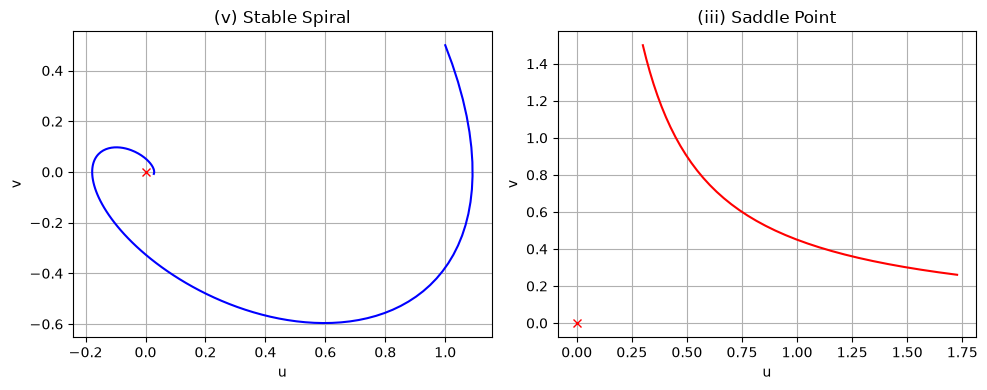

In [4]:
# Simple phase portrait check for (v) Stable Spiral and (iii) Saddle
def run_rk4(J, X0, t_end=4.0, dt=0.05):
    t = np.arange(0, t_end, dt)
    X = np.zeros((2, len(t)))
    X[:, 0] = X0
    for i in range(len(t) - 1):
        k1 = J @ X[:, i]
        k2 = J @ (X[:, i] + 0.5 * dt * k1)
        k3 = J @ (X[:, i] + 0.5 * dt * k2)
        k4 = J @ (X[:, i] + dt * k3)
        X[:, i + 1] = X[:, i] + dt * (k1 + 2*k2 + 2*k3 + k4) / 6
    return X

X_spiral = run_rk4(matrices['(v)'],   [1.0, 0.5], t_end=8.0)
X_saddle = run_rk4(matrices['(iii)'], [0.3, 1.5], t_end=1.8)

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(X_spiral[0], X_spiral[1], 'b-')
plt.plot(0, 0, 'rx')
plt.title('(v) Stable Spiral')
plt.xlabel('u'); plt.ylabel('v'); plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(X_saddle[0], X_saddle[1], 'r-')
plt.plot(0, 0, 'rx')
plt.title('(iii) Saddle Point')
plt.xlabel('u'); plt.ylabel('v'); plt.grid(True)

plt.tight_layout()
plt.show()

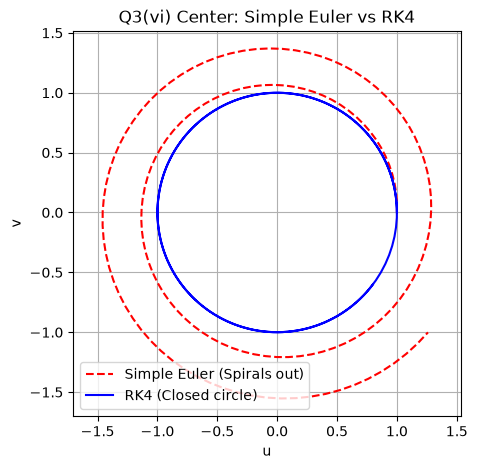

In [5]:
# Q3 (vi): J = [[0, -1], [1, 0]] is a Center (eigenvalues +/- 1j)
# Why Simple Euler fails: |1 +/- 1j*dt| = sqrt(1 + dt^2) > 1, so radius grows every step!
J_vi = matrices['(vi)']
dt = 0.08
t = np.arange(0, 12.0, dt)
n = len(t)

X_eu = np.zeros((2, n))
X_rk = run_rk4(J_vi, [1.0, 0.0], t_end=12.0, dt=dt)
X_eu[:, 0] = [1.0, 0.0]

for i in range(n - 1):
    X_eu[:, i + 1] = X_eu[:, i] + dt * (J_vi @ X_eu[:, i])

plt.figure(figsize=(5, 5))
plt.plot(X_eu[0], X_eu[1], 'r--', label='Simple Euler (Spirals out)')
plt.plot(X_rk[0], X_rk[1], 'b-', label='RK4 (Closed circle)')
plt.xlabel('u')
plt.ylabel('v')
plt.title('Q3(vi) Center: Simple Euler vs RK4')
plt.legend()
plt.grid(True)
plt.axis('equal')
plt.show()